# Godot: the life of a node, the life of a frame

Two separate clocks run in every Godot game:

| Clock | What it is | How often |
|---|---|---|
| **Node lifecycle** | A node is born, joins the tree, leaves the tree, dies | A few one-off events per node |
| **Frame loop** | The engine ticks every node that is in the tree | Forever, ~60 times a second |

The short version: **the lifecycle decides *whether* a node is in the loop; the frame loop decides *when* it gets called.**

## 1. The life of one node

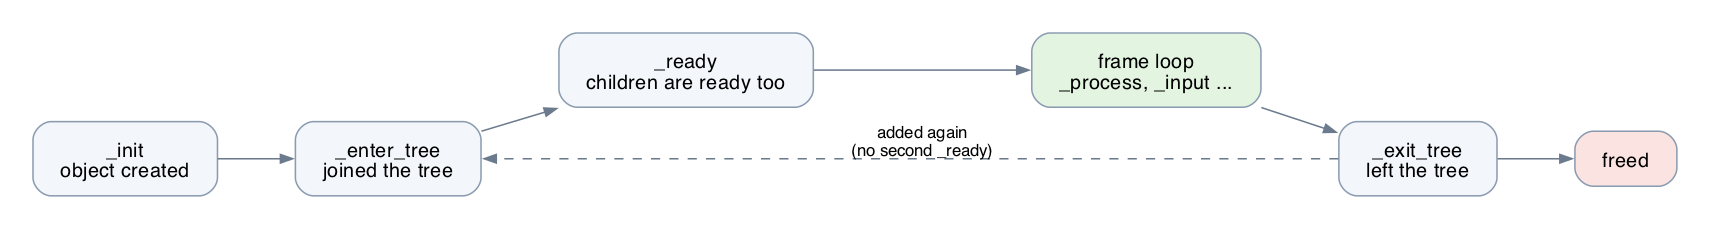

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  init  [label="_init\nobject created"];
  enter [label="_enter_tree\njoined the tree"];
  ready [label="_ready\nchildren are ready too"];
  loop  [label="frame loop\n_process, _input ...", fillcolor="#e3f4e1"];
  exit  [label="_exit_tree\nleft the tree"];
  dead  [label="freed", fillcolor="#fbe3e1"];
  init -> enter -> ready -> loop -> exit -> dead;
  exit -> enter [style=dashed, label="added again\n(no second _ready)"];
}
```

</details>

| Callback | Fires when | Runs | Safe to touch | Typical use |
|---|---|---|---|---|
| `_init` | The object is created (`.new()` / scene instanced) | Once | Only itself — no tree, no children | Default values |
| `_enter_tree` | The node joins the scene tree | **Every** time it is added | Itself and its parent | Register with something outside itself |
| `_ready` | The node **and all its children** are in the tree | Once | Children, `$Paths`, `@onready` vars | Almost all setup |
| `_exit_tree` | The node is about to leave the tree | **Every** time it is removed | Still has its children | Undo what `_enter_tree` did, stop audio |
| *(freed)* | `queue_free()` / `free()` | Once | Nothing | — |

Three things worth remembering:

- `@onready var x = $Child` is filled in **just before** `_ready`.
- In `_init`, exported values set in the Inspector are **not applied yet**. Read them in `_ready`.
- A node can exist without being in the tree (after `_init`, or after `remove_child`). It is alive, but the frame loop ignores it.

## 2. Order across a tree

With more than one node, the order matters. Take this tiny tree:

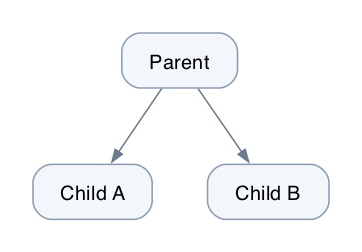

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  rankdir=TB;
  P [label="Parent"];
  A [label="Child A"];
  B [label="Child B"];
  P -> A; P -> B;
}
```

</details>

| Callback | Direction | Order for this tree | Why |
|---|---|---|---|
| `_enter_tree` | Top-down | Parent, Child A, Child B | A child can rely on its parent being in the tree |
| `_ready` | Bottom-up | Child A, Child B, Parent | A parent can rely on its children being ready |
| `_exit_tree` | Bottom-up | Child A, Child B, Parent | Children get to clean up while the parent still exists |

The cell below is a tiny Python imitation of Godot's rules, so you can change the tree and watch the order.

In [ ]:
class Node:
    def __init__(self, name, *children):
        self.name, self.children = name, list(children)
        self.was_ready = False
        print(f"_init        {name}")

def enter(node):                      # top-down
    print(f"_enter_tree  {node.name}")
    for c in node.children: enter(c)

def ready(node):                      # bottom-up, only once per node
    for c in node.children: ready(c)
    if not node.was_ready:
        print(f"_ready       {node.name}")
        node.was_ready = True

def exit_(node):                      # bottom-up
    for c in node.children: exit_(c)
    print(f"_exit_tree   {node.name}")

def add_to_tree(node):    enter(node); ready(node)
def remove_from_tree(node): exit_(node)

tree = Node("Parent", Node("Child A"), Node("Child B"))
print("--- add_child ---");      add_to_tree(tree)
print("--- remove_child ---");   remove_from_tree(tree)
print("--- add_child again ---"); add_to_tree(tree)   # note: no _ready this time

_init        Child A
_init        Child B
_init        Parent
--- add_child ---
_enter_tree  Parent
_enter_tree  Child A
_enter_tree  Child B
_ready       Child A
_ready       Child B
_ready       Parent
--- remove_child ---
_exit_tree   Child A
_exit_tree   Child B
_exit_tree   Parent
--- add_child again ---
_enter_tree  Parent
_enter_tree  Child A
_enter_tree  Child B


In [ ]:
# ----- student scratchpad ----- 


## 3. The life of one frame

Every frame the engine walks the tree and runs the same steps, in the same order:

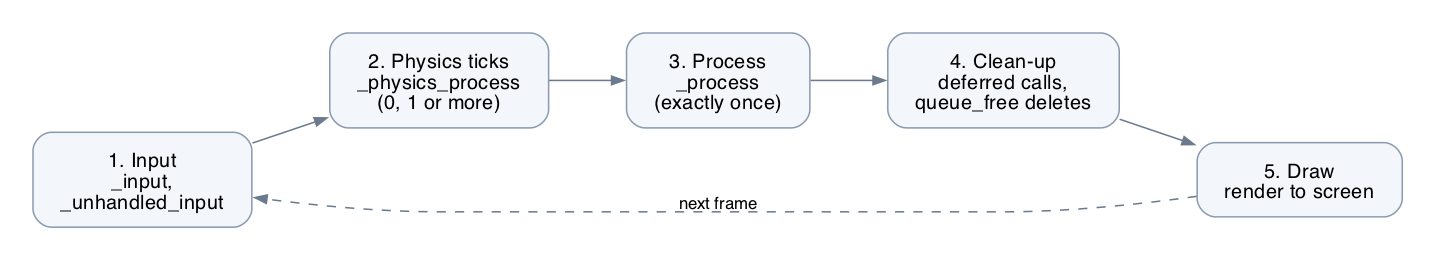

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  inp  [label="1. Input\n_input,\n_unhandled_input"];
  phys [label="2. Physics ticks\n_physics_process\n(0, 1 or more)"];
  proc [label="3. Process\n_process\n(exactly once)"];
  flush[label="4. Clean-up\ndeferred calls,\nqueue_free deletes"];
  draw [label="5. Draw\nrender to screen"];
  inp -> phys -> proc -> flush -> draw;
  draw -> inp [style=dashed, label="next frame"];
}
```

</details>

| Step | Callback | `delta` | Use it for |
|---|---|---|---|
| Input | `_input`, `_unhandled_input` (and `_gui_input` on Controls) | — | Reacting to a key / click / touch event |
| Physics tick | `_physics_process(delta)` | Fixed (1/60 s by default) | Movement, collisions, anything that must be stable |
| Process | `_process(delta)` | Varies with frame rate | Visuals, animation, timers, UI |
| Clean-up | `call_deferred`, `queue_free` | — | "Do this once the current step is finished" |
| Draw | `_draw` (only when a redraw was requested) | — | Custom 2D drawing |

Who goes first inside a step:

| Callback | Order across the tree |
|---|---|
| `_process`, `_physics_process` | Parent before children (change with `process_priority`) |
| `_input`, `_unhandled_input` | Reverse — the deepest / last nodes get the event first |

This is a simplification: clean-up also runs after each physics tick, and exactly when input is delivered varies by platform.

### Why physics can tick 0, 1 or 2 times per frame

Physics runs on a **fixed** clock (60 ticks/s). Rendering runs as fast, or as slow, as the machine allows.
Each frame, the engine runs as many physics ticks as are needed to catch up with real time.

In [ ]:
def simulate(fps, physics_tps=60, frames=8):
    frame_time, tick_time = 1 / fps, 1 / physics_tps
    owed = 0.0                          # real time physics still has to catch up on
    print(f"--- rendering at {fps} fps, physics at {physics_tps} ticks/s ---")
    for frame in range(1, frames + 1):
        owed += frame_time
        ticks = 0
        while owed >= tick_time - 1e-9:
            owed -= tick_time
            ticks += 1
        print(f"frame {frame}:  " + "_physics_process  " * ticks + "_process")

simulate(fps=60)    # one tick per frame
simulate(fps=30)    # slow machine: two ticks per frame
simulate(fps=144)   # fast monitor: many frames have no tick at all

--- rendering at 60 fps, physics at 60 ticks/s ---
frame 1:  _physics_process  _process
frame 2:  _physics_process  _process
frame 3:  _physics_process  _process
frame 4:  _physics_process  _process
frame 5:  _physics_process  _process
frame 6:  _physics_process  _process
frame 7:  _physics_process  _process
frame 8:  _physics_process  _process
--- rendering at 30 fps, physics at 60 ticks/s ---
frame 1:  _physics_process  _physics_process  _process
frame 2:  _physics_process  _physics_process  _process
frame 3:  _physics_process  _physics_process  _process
frame 4:  _physics_process  _physics_process  _process
frame 5:  _physics_process  _physics_process  _process
frame 6:  _physics_process  _physics_process  _process
frame 7:  _physics_process  _physics_process  _process
frame 8:  _physics_process  _physics_process  _process
--- rendering at 144 fps, physics at 60 ticks/s ---
frame 1:  _process
frame 2:  _process
frame 3:  _physics_process  _process
frame 4:  _process
frame 5:  _physi

In [ ]:
# ----- student scratchpad ----- 


## 4. How the two clocks relate

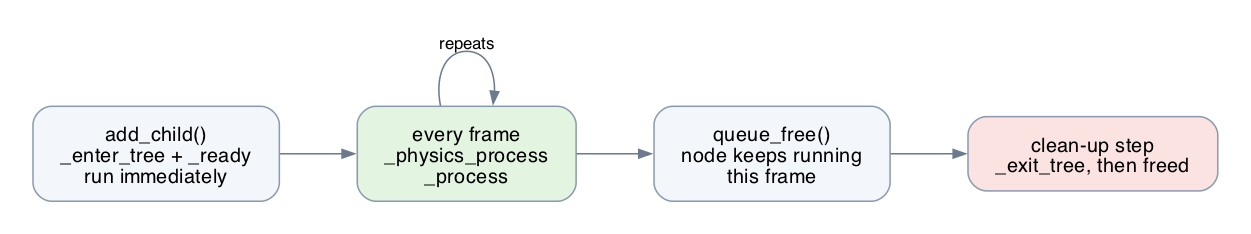

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  a [label="add_child()\n_enter_tree + _ready\nrun immediately"];
  b [label="every frame\n_physics_process\n_process", fillcolor="#e3f4e1"];
  c [label="queue_free()\nnode keeps running\nthis frame"];
  d [label="clean-up step\n_exit_tree, then freed", fillcolor="#fbe3e1"];
  a -> b -> c -> d;
  b -> b [label="repeats"];
}
```

</details>

| Question | Answer |
|---|---|
| When do lifecycle callbacks run? | Immediately, inside whatever called `add_child` / `remove_child` — they do not wait for a frame step |
| When does a node start getting `_process`? | Only after `_ready`. `_ready` always comes before the first `_process` |
| When does it stop? | At `_exit_tree`. A node outside the tree gets no frame callbacks at all |
| What does `queue_free()` do? | Marks the node; it is removed and freed in the **clean-up step**, so the rest of the frame can still use it safely |
| What does `call_deferred()` do? | Postpones a call to the clean-up step — the usual fix for "can't change the tree while it is busy" errors |
| What does pausing / `PROCESS_MODE_DISABLED` do? | Turns off the **frame** callbacks only. The node stays in the tree and lifecycle callbacks still fire |
| Do signals and `await` respect that? | No — they still fire on a disabled node |

### In this repo

`_Core` boots every scene suspended (`PROCESS_MODE_DISABLED` + viewport `UPDATE_DISABLED`):

| Clock | Suspended scene |
|---|---|
| Lifecycle (`_init`, `_enter_tree`, `_ready`) | Already ran — the scene is in the tree and fully set up |
| Frame loop (`_process`, `_physics_process`, `_input`) | Switched off until `_resume()` |
| Signals, coroutines, audio | Not part of either clock, so they keep going |

## 5. Cheat sheet

| I want to... | Put it in |
|---|---|
| Set default values | `_init` |
| Grab child nodes, connect signals, do setup | `_ready` |
| Register / unregister with something outside the node | `_enter_tree` / `_exit_tree` |
| Move things with physics | `_physics_process` |
| Animate, update UI, run timers | `_process` |
| React to a key or click | `_input` / `_unhandled_input` |
| Change the tree safely mid-frame | `call_deferred` / `queue_free` |